# 08 – Carte de scénarios 2027

**Objectif :** une page web interactive où l'on choisit un **niveau de scénario** (optimiste, central, pessimiste) et une **semaine de 2027**, et où la carte montre les communes à surveiller.

## Leçon 1 – Prévision vs scénario

Pour un jour de 2027, le modèle aurait besoin de la météo de ce jour (et des 30 précédents) : **elle n'existe pas encore**. Plutôt que d'inventer un chiffre, on fait comme en planification de la demande : on construit des **scénarios**.

> « Dans une année typique, quelles communes faut-il surveiller, et à partir de quelle semaine ? Et dans une mauvaise année, une sur dix ? »

## Leçon 2 – Un ensemble plutôt qu'une année

Une première version de ce notebook choisissait **une** année par scénario (« été sec = 2017 »). Problème : un été, c'est un seul tirage. Ce qui le rend dangereux dépend aussi du **calendrier** des coups de mistral et des canicules, en partie dû au hasard. Et l'étiquette peut tromper : on verra plus bas que la météo de 2022 (l'année record de feux) ne donne **pas** le pire été selon le modèle.

La méthode robuste, utilisée en météorologie saisonnière comme en prévision de demande :
1. on fait tourner le modèle avec la météo de **chacune des 10 années** (2016-2025) : 10 « futurs possibles » pour 2027 – on appelle ça un **ensemble** ;
2. pour chaque commune et chaque semaine, on obtient 10 valeurs, qu'on résume par des **quantiles** :
   - **P10 – optimiste** : seule 1 année sur 10 fait mieux ;
   - **P50 – central** (la médiane) : l'année typique ;
   - **P90 – pessimiste** : le risque d'une année sur 10.

> C'est exactement la **prévision par quantiles** : plutôt qu'un chiffre unique, une fourchette qui dit à quel point on est incertain.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier

df = pd.read_csv("../data/processed/features_13.csv", dtype={"code": str}, parse_dates=["jour"])
communes = pd.read_csv("../data/processed/communes_13.csv", dtype={"code": str})
df = df.merge(communes[["code", "lat", "lon"]], on="code", how="left")
df["annee"] = df["jour"].dt.year
print(df.shape)

(434707, 25)


## Étape 1 – Réentraîner sur toutes les données

Au notebook 06, on a gardé 2023-2025 sous clé pour **mesurer** honnêtement le modèle. Cette mesure est faite (et réussie). Maintenant, pour **s'en servir**, on veut qu'il ait vu le plus d'exemples possible : on le réentraîne sur **2016-2025**, avec **exactement les mêmes features et réglages** (ceux qu'on a validés).

C'est la pratique standard : *on valide sur une partie, puis on entraîne le modèle de production sur tout.*

In [2]:
FEATURES = [
    "mois", "jour_annee", "jour_semaine", "week_end",
    "temp_max", "humidite_min", "vent_max", "pluie", "evapo",
    "pluie_7j", "pluie_30j", "evapo_30j", "temp_max_7j", "bilan_hydrique_30j",
    "jours_sans_pluie", "vent_fort",
    "feux_commune_365j", "feux_commune_cumul", "feux_dept_veille",
    "lat", "lon",
]
REGLAGES = dict(
    learning_rate=0.03, max_iter=300, early_stopping=False,
    max_leaf_nodes=7, min_samples_leaf=1000, random_state=42,
)

modele = HistGradientBoostingClassifier(**REGLAGES)
modele.fit(df[FEATURES], df["feu"])
print("Modèle entraîné sur", len(df), "lignes et", df["feu"].sum(), "jours avec feu")

Modèle entraîné sur 434707 lignes et 2480 jours avec feu


## Étape 2 – Fabriquer les features « 2027 » d'une année de météo

Pour rejouer la météo de l'année Y, on prend ses lignes (119 communes × 365 jours) et on **garde** le calendrier et toute la **météo** de Y.

On **remplace** les features d'historique, qui doivent refléter la situation **connue avant 2027** :
- `feux_commune_365j` → le nombre de jours avec feu de chaque commune **en 2025** (la dernière année connue) ;
- `feux_commune_cumul` → le total **2016-2025** de chaque commune ;
- `feux_dept_veille` → on ne connaît pas l'activité de feux de 2027 ; on met la **moyenne observée pour ce jour de l'année** sur 2016-2025.

### Leçon 3 – Ne pas tricher, même dans un scénario
Pourquoi ne pas garder le `feux_dept_veille` réel de 2022 ? Parce qu'il contient **les feux de 2022** : rejouer 2022 reviendrait à savoir d'avance qu'il y aura beaucoup de feux. On ne rejoue que ce qu'on pourrait vraiment supposer : la **météo**.

In [3]:
feux_2025 = df[df["annee"] == 2025].groupby("code")["feu"].sum()
feux_total = df.groupby("code")["feu"].sum()
dept_typique = df.groupby(["annee", "jour_annee"])["feu"].sum().groupby("jour_annee").mean()

def features_meteo(annee):
    s = df[df["annee"] == annee].copy()
    s["feux_commune_365j"] = s["code"].map(feux_2025)
    s["feux_commune_cumul"] = s["code"].map(feux_total)
    s["feux_dept_veille"] = s["jour_annee"].map(dept_typique)
    return s

features_meteo(2022)[["code", "jour", "temp_max", "feux_commune_365j", "feux_commune_cumul", "feux_dept_veille"]].head()

,code,jour,temp_max,feux_commune_365j,feux_commune_cumul,feux_dept_veille
2192,13001,2022-01-01,10.9,16,141,0.0
2193,13001,2022-01-02,10.3,16,141,0.0
2194,13001,2022-01-03,13.6,16,141,0.0
2195,13001,2022-01-04,14.6,16,141,0.1
2196,13001,2022-01-05,10.5,16,141,0.1


`.copy()` est important : on modifie des colonnes, et on ne veut surtout pas abîmer `df` (les vraies données).

`dept_typique` : on compte d'abord les feux de chaque jour de chaque année (`groupby(["annee", "jour_annee"])`), puis on fait la moyenne par jour de l'année.

## Étape 3 – Faire tourner les 10 années et résumer par semaine

### Leçon 4 – Probabilité d'au moins un feu dans la semaine
Le modèle donne une probabilité **par jour**. On résume par **semaine** : *« probabilité qu'au moins un feu démarre dans la commune pendant la semaine »*, en passant par le contraire :
- pas de feu un jour = `1 − p` ;
- aucun feu sur 7 jours = `(1 − p₁) × (1 − p₂) × … × (1 − p₇)` ;
- au moins un = `1 − ce produit`.

(On suppose les jours indépendants – une simplification raisonnable pour une carte de planification.) Exemple : 10 % chaque jour → 1 − 0,9⁷ ≈ **52 %** sur la semaine.

Semaines : jours 1-7 → semaine 1, 8-14 → semaine 2… les 1 ou 2 derniers jours de l'année sont rattachés à la semaine 52.

In [4]:
ANNEES = list(range(2016, 2026))

morceaux = []
for annee in ANNEES:
    X = features_meteo(annee)
    X["proba"] = modele.predict_proba(X[FEATURES])[:, 1]
    X["semaine"] = ((X["jour_annee"] - 1) // 7 + 1).clip(upper=52)
    X["pas_de_feu"] = 1 - X["proba"]
    X["meteo"] = annee
    morceaux.append(X[["meteo", "code", "semaine", "mois", "proba", "pas_de_feu"]])

jours = pd.concat(morceaux, ignore_index=True)

semaines = jours.groupby(["meteo", "code", "semaine"]).agg(
    proba_semaine=("pas_de_feu", "prod"),
    feux_attendus=("proba", "sum"),
).reset_index()
semaines["proba_semaine"] = 1 - semaines["proba_semaine"]
print(semaines.shape)   # attendu : 10 années × 119 communes × 52 semaines = 61 880

(61880, 5)


`//` est la **division entière** (15 // 7 = 2) ; `.clip(upper=52)` plafonne à 52.

### Le bilan, année de météo par année de météo

In [5]:
bilan = jours.groupby("meteo").agg(feux_attendus_an=("proba", "sum"))
bilan["dont_juillet_aout"] = jours[jours["mois"].isin([7, 8])].groupby("meteo")["proba"].sum()
bilan["feux_reels_cette_annee"] = df.groupby("annee")["feu"].sum()
bilan.sort_values("feux_attendus_an").round(0)

,feux_attendus_an,dont_juillet_aout,feux_reels_cette_annee
meteo,,,
2018,249.0,131.0,107
2024,256.0,141.0,207
2025,290.0,151.0,252
2021,305.0,153.0,279
2020,327.0,177.0,227
2023,329.0,165.0,269
2016,347.0,168.0,338
2019,370.0,155.0,188
2022,374.0,150.0,404


**Deux enseignements :**
1. La **fourchette** est large : selon la météo rejouée, l'année va du simple à environ 1,5 fois. C'est cette incertitude que les quantiles vont résumer.
2. **La météo de 2022 ne donne pas le pire été** selon le modèle, alors que 2022 a été l'année record de feux réels. Une partie de ce record ne vient donc pas de la seule météo de l'été (historique de feux de cette année-là, facteurs humains…). C'est précisément pourquoi on ne bâtit pas un scénario sur **une** année « étiquetée ».

## Étape 4 – Les quantiles

Pour chaque commune et chaque semaine, on prend les 10 valeurs (une par année de météo) et on calcule P10, P50 et P90. `quantile([0.1, 0.5, 0.9])` fait ça d'un coup ; `unstack()` met les trois résultats en colonnes.

In [6]:
quantiles = (semaines.groupby(["code", "semaine"])["proba_semaine"]
             .quantile([0.1, 0.5, 0.9]).unstack())
quantiles.columns = ["p10", "p50", "p90"]
quantiles.loc["13056"].loc[26:32]   # Martigues, du début à la fin de juillet

,p10,p50,p90
semaine,,,
26,0.399410,0.636463,0.708184
27,0.568358,0.747167,0.854561
28,0.608010,0.717952,0.822621
29,0.645187,0.684830,0.752320
30,0.633124,0.690838,0.723322
31,0.610314,0.694107,0.811056
32,0.474691,0.585157,0.794252


Lecture pour Martigues : une semaine de juillet typique (P50) donne une forte probabilité d'au moins un départ ; l'écart entre P10 et P90 montre la marge d'incertitude liée à la météo.

### Attention au total du département
On **ne peut pas additionner** les P90 des communes pour obtenir le P90 du département : toutes les communes ne vivent pas leur « mauvaise année » en même temps. On calcule donc le total du département **pour chaque année de météo**, puis on prend les quantiles de ces totaux.

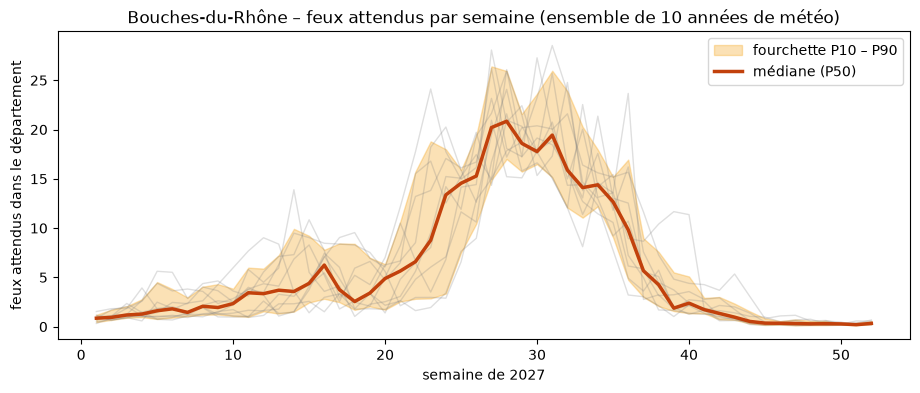

In [7]:
dept_par_annee = semaines.groupby(["meteo", "semaine"])["feux_attendus"].sum().unstack("meteo")
dept = pd.DataFrame({
    "p10": dept_par_annee.quantile(0.1, axis=1),
    "p50": dept_par_annee.quantile(0.5, axis=1),
    "p90": dept_par_annee.quantile(0.9, axis=1),
})

fig, ax = plt.subplots(figsize=(11, 4))
for annee in ANNEES:
    ax.plot(dept_par_annee.index, dept_par_annee[annee], color="grey", alpha=0.25, linewidth=1)
ax.fill_between(dept.index, dept["p10"], dept["p90"], color="#f59e0b", alpha=0.3, label="fourchette P10 – P90")
ax.plot(dept.index, dept["p50"], color="#c2410c", linewidth=2.5, label="médiane (P50)")
ax.set_xlabel("semaine de 2027")
ax.set_ylabel("feux attendus dans le département")
ax.set_title("Bouches-du-Rhône – feux attendus par semaine (ensemble de 10 années de météo)")
ax.legend()
plt.show()

- Chaque trait gris = une année de météo rejouée ;
- la **bande orange** = là où se trouvent 80 % des années (P10 → P90) ;
- le **trait foncé** = l'année typique.

`fill_between` colorie l'espace entre deux courbes ; `alpha` règle la transparence.

L'hiver, la bande est fine (peu d'incertitude : le risque est faible quoi qu'il arrive) ; l'été, elle s'élargit : c'est là que la météo fait toute la différence.

## Étape 5 – Construire la page web

### Leçon 5 – Pourquoi tout précalculer ?
Une page web ne sait pas exécuter notre modèle Python. Mais il n'y a que quelques dizaines de milliers de valeurs à afficher (3 niveaux × 119 communes × 52 semaines, plus les indicateurs de saison et l'historique) : on les calcule **toutes maintenant**, on les range dans un **JSON**, et la page n'a plus qu'à afficher la bonne valeur quand on bouge un curseur. Résultat : un simple fichier HTML, sans serveur, hébergeable gratuitement (GitHub Pages).

La page elle-même (filtres, carte, fiche commune, graphiques) est écrite en HTML/JavaScript dans `src/carte_scenarios_template.html`. Elle contient deux « trous », `__DATA__` et `__GEO__`, que Python remplit.

### Les indicateurs supplémentaires du tableau de bord

La page propose trois modes d'affichage et une **fiche par commune**. Il nous faut donc, en plus des probabilités hebdomadaires :

1. la **saison** (juin à septembre) : le **nombre de jours avec feu attendus** (somme des probabilités), et la probabilité d'au moins un feu sur toute la saison (`1 − ∏(1 − p)`), chacun en quantiles. Pourquoi les deux ? Sur 4 mois, la probabilité d'au moins un feu dépasse 50 % dans la plupart des communes : elle ne permet plus de les distinguer. Le **nombre attendu**, lui, va de presque 0 à plus de 15 et se compare directement à l'historique ;
2. le **nombre de jours avec feu attendus sur l'année**, par commune (somme des probabilités), en quantiles ;
3. l'**historique réel** de chaque commune, tiré directement de l'export BDIFF : nombre de feux, surface brûlée, répartition par année et par mois.

`1 - serie` fonctionne sur toute une colonne d'un coup (calcul **vectorisé**) : pas besoin de boucle.

In [8]:
# 1. risque sur la saison (juin → septembre), par année de météo puis en quantiles
saison_par_annee = 1 - jours[jours["mois"].between(6, 9)].groupby(["meteo", "code"])["pas_de_feu"].prod()
saison = saison_par_annee.groupby("code").quantile([0.1, 0.5, 0.9]).unstack()
saison.columns = ["p10", "p50", "p90"]

# 2. jours avec feu attendus sur l'année, par commune
annuel_par_annee = jours.groupby(["meteo", "code"])["proba"].sum()
annuel = annuel_par_annee.groupby("code").quantile([0.1, 0.5, 0.9]).unstack()
annuel.columns = ["p10", "p50", "p90"]

# jours avec feu attendus de juin à septembre, par commune
saison_jours_par_annee = jours[jours["mois"].between(6, 9)].groupby(["meteo", "code"])["proba"].sum()
saison_jours = saison_jours_par_annee.groupby("code").quantile([0.1, 0.5, 0.9]).unstack()
saison_jours.columns = ["p10", "p50", "p90"]

# totaux du département (quantiles des totaux, pas somme des quantiles !)
dept_saison = jours[jours["mois"].between(6, 9)].groupby("meteo")["proba"].sum().quantile([0.1, 0.5, 0.9])
dept_saison.index = ["p10", "p50", "p90"]

# 3. historique réel depuis la BDIFF
brut = pd.read_csv("../data/raw/Incendies.csv", sep=";", skiprows=3, encoding="utf-8",
                   dtype={"Département": str, "Code INSEE": str})
brut = brut[brut["Département"] == "13"].copy()
brut["date"] = pd.to_datetime(brut["Date de première alerte"])

nb_feux = brut.groupby("Code INSEE").size()
surface_ha = brut.groupby("Code INSEE")["Surface parcourue (m2)"].sum() / 10_000
par_annee = (brut.groupby(["Code INSEE", brut["date"].dt.year]).size()
             .unstack(fill_value=0).reindex(columns=ANNEES, fill_value=0))
par_mois = (brut.groupby(["Code INSEE", brut["date"].dt.month]).size()
            .unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0))
jours_avec_feu = df.groupby("code")["feu"].sum()
jours_avec_feu_ete = df[df["mois"].between(6, 9)].groupby("code")["feu"].sum()

print("Martigues :", nb_feux["13056"], "feux,", round(surface_ha["13056"]), "ha,",
      "risque saison central :", round(saison.loc["13056", "p50"], 2))

Martigues : 224 feux, 1459 ha, risque saison central : 1.0


`reindex(columns=ANNEES, fill_value=0)` garantit qu'on a **toutes** les années en colonnes, avec 0 pour les années sans feu (sinon une commune qui n'a pas brûlé en 2018 n'aurait tout simplement pas de colonne 2018).

On assemble tout dans un grand dictionnaire, au format attendu par la page. `int(...)` et `float(...)` convertissent les nombres numpy en nombres Python « simples », que le format JSON sait écrire.

In [9]:
NIVEAUX = [
    {"id": "p10", "nom": "Optimiste", "detail": "1 année sur 10 fait mieux"},
    {"id": "p50", "nom": "Central", "detail": "année typique (médiane)"},
    {"id": "p90", "nom": "Pessimiste", "detail": "1 année sur 10 fait pire"},
]

fiche = {}
for _, c in communes.iterrows():
    code = c["code"]
    fiche[code] = {
        "nom": c["nom"], "lat": round(c["lat"], 4), "lon": round(c["lon"], 4),
        "feux": int(nb_feux.get(code, 0)),
        "jours": int(jours_avec_feu.get(code, 0)),
        "jours_ete": int(jours_avec_feu_ete.get(code, 0)),
        "surface": round(float(surface_ha.get(code, 0)), 1),
        "par_annee": [int(v) for v in par_annee.loc[code]] if code in par_annee.index else [0] * len(ANNEES),
        "par_mois": [int(v) for v in par_mois.loc[code]] if code in par_mois.index else [0] * 12,
    }

donnees = {
    "niveaux": NIVEAUX,
    "annees": ANNEES,
    "communes": fiche,
    "semaine": {},
    "saison": {n["id"]: {code: round(float(v), 4) for code, v in saison[n["id"]].items()} for n in NIVEAUX},
    "saison_jours": {n["id"]: {code: round(float(v), 2) for code, v in saison_jours[n["id"]].items()} for n in NIVEAUX},
    "annuel": {n["id"]: {code: round(float(v), 2) for code, v in annuel[n["id"]].items()} for n in NIVEAUX},
    "dept": {n["id"]: [round(float(v), 2) for v in dept[n["id"]]] for n in NIVEAUX},
    "dept_saison": {k: round(float(v), 1) for k, v in dept_saison.items()},
    "total_feux": int(len(brut)),
    "total_jours": int(df["feu"].sum()),
}
for n in NIVEAUX:
    tableau = quantiles[n["id"]].unstack("semaine")
    donnees["semaine"][n["id"]] = {code: [round(float(v), 4) for v in ligne]
                                   for code, ligne in zip(tableau.index, tableau.values)}

print(len(donnees["communes"]), "communes,", len(donnees["semaine"]["p50"]["13056"]), "semaines")
print("Martigues, semaine 30 :", {n["id"]: donnees["semaine"][n["id"]]["13056"][29] for n in NIVEAUX})

119 communes, 52 semaines
Martigues, semaine 30 : {'p10': 0.6331, 'p50': 0.6908, 'p90': 0.7233}


`{cle: valeur for ... in ...}` est une **compréhension de dictionnaire**. `[29]` → la **30ᵉ** semaine (Python compte à partir de 0).

Ensuite les contours des communes, dont on **arrondit les coordonnées** à 4 décimales (≈ 10 m) pour alléger la page :

In [10]:
contours = json.loads(Path("../data/raw/communes_13.geojson").read_text(encoding="utf-8"))

def arrondir(coords):
    if isinstance(coords[0], (int, float)):
        return [round(coords[0], 4), round(coords[1], 4)]
    return [arrondir(c) for c in coords]

for f in contours["features"]:
    f["geometry"]["coordinates"] = arrondir(f["geometry"]["coordinates"])

`arrondir` est une fonction **récursive** : elle s'appelle elle-même. Un polygone est une liste de listes de points (parfois une liste de listes de listes !) ; la fonction descend jusqu'à tomber sur un point `[lon, lat]`, qu'elle arrondit.

Enfin, on remplit le gabarit et on écrit la page :

In [11]:
gabarit = Path("../src/carte_scenarios_template.html").read_text(encoding="utf-8")
page = (gabarit
        .replace("__DATA__", json.dumps(donnees, ensure_ascii=False))
        .replace("__GEO__", json.dumps(contours, ensure_ascii=False)))

sortie = Path("../outputs/carte_scenarios_2027.html")
sortie.parent.mkdir(exist_ok=True)
sortie.write_text(page, encoding="utf-8")
print(f"Page écrite : {sortie.resolve()}  ({sortie.stat().st_size / 1e6:.1f} Mo)")

Page écrite : /Users/duvalthomas/ml-projets/incendies/outputs/carte_scenarios_2027.html  (1.5 Mo)


- `json.dumps(...)` transforme un objet Python en texte JSON ; `ensure_ascii=False` garde les accents lisibles.
- `.replace("__DATA__", ...)` remplace le « trou » du gabarit par les données.

👉 **Ouvre `outputs/carte_scenarios_2027.html` dans ton navigateur** et explore :
- **clique sur une commune** : sa fiche affiche ses feux passés (par année, par mois) et sa courbe de risque 2027 ;
- passe d'**Optimiste** à **Pessimiste** en plein été : quelles communes basculent ?
- lance l'**animation** ▶ des semaines, ou clique directement sur le graphique du département ;
- n'affiche que les risques **Élevé** et **Très élevé** ;
- compare le mode **Feux passés** avec le mode **Saison juin-sept.**, ou coche « Superposer les feux passés » : le risque prédit suit-il l'historique ?

**À toi de jouer :** dans le scénario **central**, à partir de quelle semaine Martigues dépasse-t-elle 50 % ? Trouve la réponse dans la page (fiche de Martigues), puis vérifie en Python avec `donnees["semaine"]["p50"]["13056"]`.

In [12]:
# à toi

## Récap du notebook

1. **On ne prédit pas 2027 au jour près** (météo inconnue) : on fait de la **planification par scénarios**.
2. **Ensemble de 10 années de météo** plutôt qu'une année par scénario : plus robuste, et on voit l'incertitude.
3. **Quantiles P10 / P50 / P90** par commune et par semaine ; pour le département, quantiles des **totaux annuels** (on n'additionne pas des P90).
4. Dans un scénario, on ne rejoue que la **météo** ; l'historique de feux est celui connu fin 2025.
5. **Tout précalculer** → une page HTML autonome (Leaflet + JSON) : filtres, fiche commune avec historique réel et risque 2027.

**Pistes :** la météo remonte bien avant 2016 (Open-Meteo : 1940) – le modèle a besoin des feux pour **apprendre**, mais les scénarios n'ont besoin que de **météo** : on pourrait construire un ensemble de 30 étés. Pondérer davantage les années récentes (réchauffement).

**Limites à écrire dans le README :** 10 années seulement ; le climat de 2027 pourrait sortir de cette plage ; calibration (surestimation ≈ 25 % du niveau sur 2023-2025) ; indépendance des jours supposée ; météo à 10 km de résolution.